# Classificação de Candidatos a Pulsares (Base HTRU2)

**Disciplina:** Introdução ao Aprendizado de Máquina  
**Base de Dados:** `CMPINAM_Dataset_07_HTRU2_Pulsar` (High Time Resolution Universe Survey)  

---

## 1. Base e Preparação

### 1.1 Origem e Descrição do Problema
Pulsares são estrelas de nêutrons altamente magnetizadas e de rotação rápida que emitem feixes de radiação eletromagnética detectáveis por radiotelescópios na Terra como pulsos periódicos. Na prática observacional, a grande maioria dos sinais periódicos captados corresponde a interferências de radiofrequência (RFI) e ruído instrumental, tornando a triagem automática um problema crítico na radioastronomia.

A base **HTRU2** (*High Time Resolution Universe Survey*) reúne **17.898 candidatos** coletados durante levantamentos astronômicos no radiotelescópio Parkes, já divididos previamente pela disciplina em:
* **Conjunto de Treino (`train.csv`):** 14.318 instâncias (80%).
* **Conjunto de Teste (`test.csv`):** 3.580 instâncias (20%).

Cada linha representa um **candidato a pulsar** descrito por **8 atributos contínuos** (`float64`) extraídos de duas curvas diagnósticas e **1 variável-alvo binária** (`int64`):

| Atributo | Descrição Física / Estatística |
| :--- | :--- |
| `mean_integrated_profile` | Média do perfil de pulso integrado (intensidade média do sinal dobrado no período). |
| `std_integrated_profile` | Desvio padrão do perfil de pulso integrado. |
| `excess_kurtosis_integrated_profile` | Excesso de curtose do perfil integrado (mede o quão agudo é o pico em relação à normal). |
| `skewness_integrated_profile` | Assimetria (*skewness*) do perfil integrado. |
| `mean_dm_snr_curve` | Média da curva DM-SNR (*Dispersion Measure - Signal-to-Noise Ratio*). |
| `std_dm_snr_curve` | Desvio padrão da curva DM-SNR. |
| `excess_kurtosis_dm_snr_curve` | Excesso de curtose da curva DM-SNR. |
| `skewness_dm_snr_curve` | Assimetria da curva DM-SNR. |
| `is_pulsar` *(Variável-Alvo)* | Classe do candidato: `0` = Não-Pulsar (ruído/RFI) e `1` = Pulsar real. |

In [ ]:
# ==============================================================================
# 0. IMPORTAÇÕES E CONFIGURAÇÃO DE REPRODUTIBILIDADE
# ==============================================================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    f1_score,
    recall_score,
    precision_score,
    average_precision_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# ==============================================================================
# 1. BASE E PREPARAÇÃO (EXCLUSIVAMENTE SOBRE O TREINO PARA EVITAR LEAKAGE)
# ==============================================================================
# Ajuste o caminho relativo caso o notebook esteja na mesma pasta dos CSVs ("train.csv")
df_train = pd.read_csv("../data/train.csv")
df_test = pd.read_csv("../data/test.csv")

print(f"Treino: {df_train.shape[0]} linhas x {df_train.shape[1]} colunas")
print(f"Teste : {df_test.shape[0]} linhas x {df_test.shape[1]} colunas")

# Verificação de qualidade dos dados no treino
print("\n--- Valores Ausentes (Treino) ---")
print(df_train.isnull().sum())

print(f"\nDuplicatas exatas (Treino): {df_train.duplicated().sum()}")
invalid_std = (df_train["std_integrated_profile"] <= 0).sum() + (df_train["std_dm_snr_curve"] <= 0).sum()
print(f"Desvios padrão <= 0 (Treino): {invalid_std}")

# Diagnóstico de Outliers via IQR (apenas diagnóstico — não serão removidos)
features = [c for c in df_train.columns if c != "is_pulsar"]
outlier_summary = []
for col in features:
    q1 = df_train[col].quantile(0.25)
    q3 = df_train[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df_train[col] < q1 - 1.5 * iqr) | (df_train[col] > q3 + 1.5 * iqr)).sum()
    outlier_summary.append({"Atributo": col, "Outliers (IQR)": n_out, "% Treino": round(n_out / len(df_train) * 100, 2)})

display(pd.DataFrame(outlier_summary))

Treino: 14318 linhas x 9 colunas
Teste : 3580 linhas x 9 colunas

--- Valores Ausentes (Treino) ---
mean_integrated_profile               0
std_integrated_profile                0
excess_kurtosis_integrated_profile    0
skewness_integrated_profile           0
mean_dm_snr_curve                     0
std_dm_snr_curve                      0
excess_kurtosis_dm_snr_curve          0
skewness_dm_snr_curve                 0
is_pulsar                             0
dtype: int64

Duplicatas exatas (Treino): 0
Desvios padrão <= 0 (Treino): 0


,Atributo,Outliers (IQR),% Treino
0,mean_integrated_profile,807,5.64
1,std_integrated_profile,203,1.42
2,excess_kurtosis_integrated_profile,1276,8.91
3,skewness_integrated_profile,1558,10.88
4,mean_dm_snr_curve,2331,16.28
5,std_dm_snr_curve,1860,12.99
6,excess_kurtosis_dm_snr_curve,385,2.69
7,skewness_dm_snr_curve,708,4.94


### 1.2 Ajustes Iniciais e Tratamento de Dados Faltantes e Outliers
Para evitar qualquer vazamento de dados (*data leakage*), toda a inspeção de integridade foi conduzida exclusivamente sobre o conjunto de treino (`train.csv`):

* **Valores ausentes e duplicatas:** Não foram encontrados valores nulos (`0` em todas as colunas) nem registros duplicados (`0` linhas repetidas).
* **Consistência física:** Verificou-se que não há desvios padrão nulos ou negativos (`std_integrated_profile > 0` e `std_dm_snr_curve > 0` em 100% das instâncias), não havendo registros inválidos a descartar.
* **Decisão sobre Outliers (Manutenção Justificada):** A análise pelo critério interquartil (IQR) apontou proporções expressivas de valores extremos — destacando-se `mean_dm_snr_curve` (16,28%), `std_dm_snr_curve` (12,99%), `skewness_integrated_profile` (10,88%) e `excess_kurtosis_integrated_profile` (8,91%). **Optou-se por manter todos os outliers**, pois, no domínio físico dos pulsares, picos estreitos e altamente assimétricos geram justamente valores elevados de curtose e assimetria. Removê-los eliminaria os próprios exemplos positivos que o modelo precisa aprender. Para lidar com essas caudas longas sem distorção, adotaremos `RobustScaler` nos modelos lineares e algoritmos baseados em árvores (invariantes a transformações monotônicas).

## 2. Análise Exploratória de Dados (EDA)

Toda a análise exploratória a seguir utiliza **estritamente o conjunto de treino** (14.318 registros) para preservar a integridade metodológica da avaliação final.

### Pergunta 1: Qual é a proporção exata entre pulsares reais e sinais de ruído?
* **Tipo de gráfico escolhido:** Gráfico de Barras (`countplot`).
* **Justificativa:** O gráfico de barras é a representação mais direta e precisa para comparar frequências absolutas e percentuais de categorias discretas.
* **Achado:** Observa-se um forte desbalanceamento: **13.007 candidatos (90,84%)** pertencem à classe `0` (não-pulsares) e apenas **1.311 candidatos (9,16%)** pertencem à classe `1` (pulsares reais), uma razão aproximada de 10:1.

### Pergunta 2: Quais são as faixas de valores, medianas e dispersões dos 8 atributos?
* **Achado:** As variáveis operam em ordens de grandeza muito distintas — por exemplo, `excess_kurtosis_integrated_profile` varia de `-1,88` a `8,07` (mediana `0,22`), enquanto `skewness_dm_snr_curve` varia de `-1,98` a `1.191,00` (mediana `83,25`). Além disso, médias muito superiores às medianas em atributos como `mean_dm_snr_curve` (média `12,37` vs. mediana `2,80`) confirmam forte assimetria positiva.

### Pergunta 3: Como se comporta a distribuição do Excesso de Curtose do Perfil Integrado?
* **Tipo de gráfico escolhido:** Histograma com estimativa de densidade por kernel (KDE).
* **Justificativa:** Permite observar simultaneamente a concentração de frequências por intervalos e o formato contínuo da cauda longa.
* **Achado:** A distribuição é fortemente concentrada próximo de zero (mediana `0,224`, onde se agrupam os ruídos gaussianos) com uma cauda alongada à direita estendendo-se até `8,07`, correspondente aos sinais impulsivos dos pulsares.

### Pergunta 4: Qual atributo concentra maior dispersão de valores extremos?
* **Tipo de gráfico escolhido:** Boxplot horizontal padronizado por IQR.
* **Justificativa:** Resume mediana, quartis e a extensão relativa dos outliers de todos os atributos lado a lado na mesma escala.
* **Achado:** Os atributos `skewness_integrated_profile`, `mean_dm_snr_curve` e `std_dm_snr_curve` concentram as maiores caudas de valores extremos acima do limite superior de Tukey ($Q_3 + 1,5 \times \text{IQR}$).

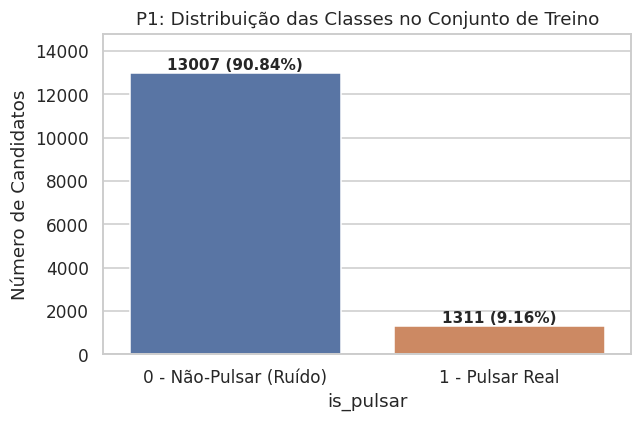

,min,25%,50%,mean,75%,max,std
mean_integrated_profile,5.812,100.877,115.066,111.057,127.141,192.617,25.584
std_integrated_profile,24.772,42.359,46.941,46.515,51.024,91.809,6.805
excess_kurtosis_integrated_profile,-1.876,0.027,0.224,0.478,0.472,8.070,1.063
skewness_integrated_profile,-1.792,-0.188,0.197,1.772,0.924,68.102,6.178
mean_dm_snr_curve,0.213,1.916,2.795,12.365,5.420,222.421,28.816
std_dm_snr_curve,7.370,14.405,18.453,26.238,28.350,110.642,19.397
excess_kurtosis_dm_snr_curve,-3.139,5.796,8.439,8.330,10.731,34.540,4.507
skewness_dm_snr_curve,-1.977,35.195,83.247,105.386,140.130,1191.001,106.912
is_pulsar,0.000,0.000,0.000,0.092,0.000,1.000,0.288


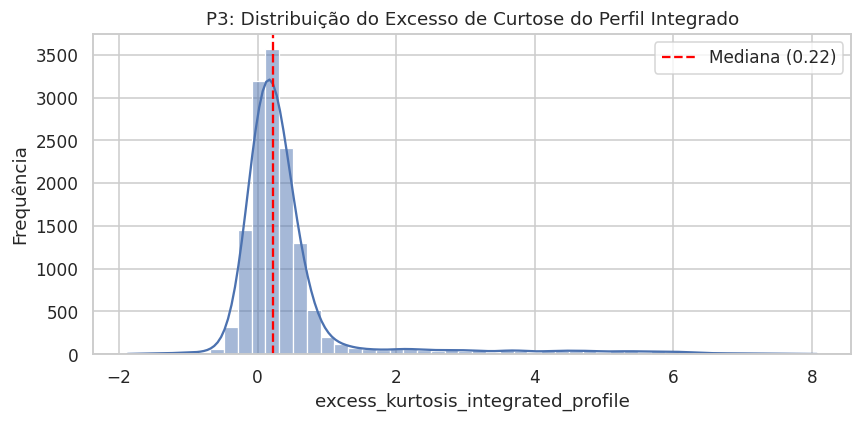

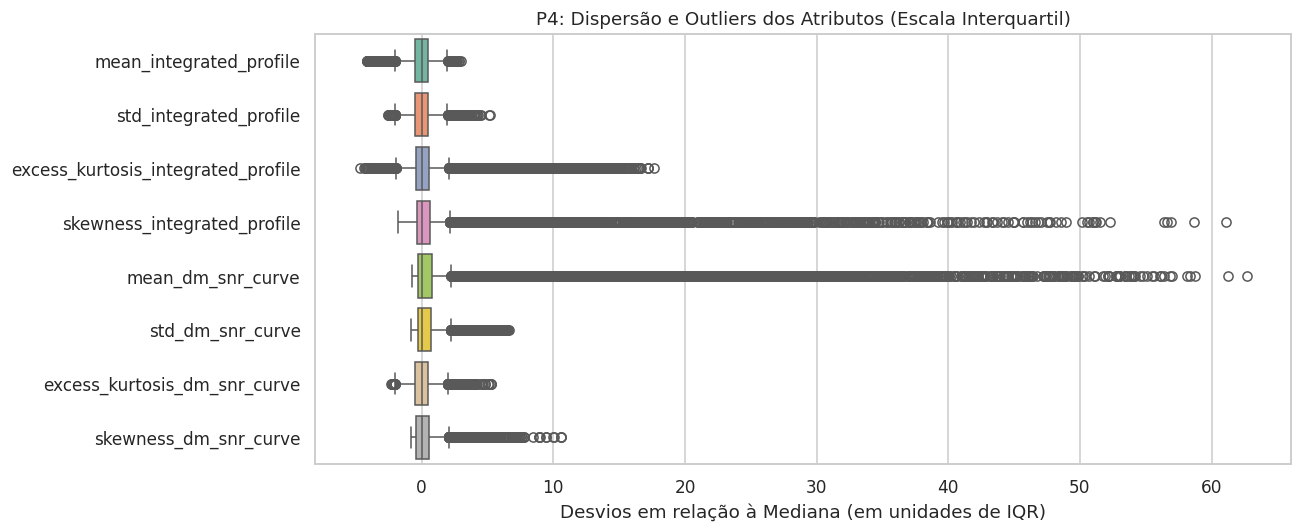

In [5]:
# ==============================================================================
# 2. ANÁLISE EXPLORATÓRIA (EDA) — 8 PERGUNTAS E 4 TIPOS DE GRÁFICOS
# ==============================================================================

# --- PERGUNTA 1: Qual é a proporção entre pulsares reais (1) e ruídos (0)? ---
# Tipo de gráfico 1: Gráfico de Barras (Countplot)
# Justificativa: Ideal para comparar diretamente as frequências absolutas e relativas de categorias discretas.
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_train, x="is_pulsar", palette=["#4C72B0", "#DD8452"])
for p in ax.patches:
    pct = 100 * p.get_height() / len(df_train)
    ax.annotate(f"{int(p.get_height())} ({pct:.2f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title("P1: Distribuição das Classes no Conjunto de Treino")
ax.set_xticklabels(["0 - Não-Pulsar (Ruído)", "1 - Pulsar Real"])
ax.set_ylabel("Número de Candidatos")
ax.set_ylim(0, 14800)
plt.tight_layout()
plt.show()

# --- PERGUNTA 2: Quais são as estatísticas centrais e de dispersão dos 8 atributos? ---
display(df_train.describe().T[["min", "25%", "50%", "mean", "75%", "max", "std"]].round(3))

# --- PERGUNTA 3: Como se distribui o Excesso de Curtose do Perfil Integrado? ---
# Tipo de gráfico 2: Histograma com curva de densidade (KDE)
# Justificativa: Permite visualizar simultaneamente a frequência por faixas e a assimetria da cauda longa da variável contínua.
plt.figure(figsize=(8, 4))
sns.histplot(df_train["excess_kurtosis_integrated_profile"], bins=50, kde=True, color="#4C72B0")
plt.axvline(df_train["excess_kurtosis_integrated_profile"].median(), color="red", linestyle="--", label="Mediana (0.22)")
plt.title("P3: Distribuição do Excesso de Curtose do Perfil Integrado")
plt.xlabel("excess_kurtosis_integrated_profile")
plt.ylabel("Frequência")
plt.legend()
plt.tight_layout()
plt.show()

# --- PERGUNTA 4: Qual atributo apresenta maior presença de valores extremos? ---
# Tipo de gráfico 3: Boxplot Padronizado (Z-score robusto apenas para visualização comparativa)
# Justificativa: Resume mediana, quartis e pontos extremos de múltiplas variáveis contínuas lado a lado na mesma escala.
df_scaled_viz = (df_train[features] - df_train[features].median()) / (
    df_train[features].quantile(0.75) - df_train[features].quantile(0.25)
)
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_scaled_viz, orient="h", palette="Set2")
plt.title("P4: Dispersão e Outliers dos Atributos (Escala Interquartil)")
plt.xlabel("Desvios em relação à Mediana (em unidades de IQR)")
plt.tight_layout()
plt.show()

### Pergunta 5 (Relação entre Variáveis 1): Como as medianas dos atributos diferem entre Pulsares e Não-Pulsares?
* **Tipo de gráfico escolhido:** Boxplots agrupados por classe.
* **Justificativa:** Evidencia deslocamentos de mediana e diferenças de dispersão interquartil de uma variável contínua entre grupos distintos.
* **Achado:** Há clara separação estatística entre os grupos:
  * **Perfil Integrado:** Pulsares possuem mediana de `excess_kurtosis_integrated_profile` quase **15 vezes maior** (`2,870` vs. `0,188`) e mediana de `mean_integrated_profile` **menos da metade** dos não-pulsares (`54,95` vs. `117,30`).
  * **Curva DM-SNR:** Pulsares apresentam dispersão (`std_dm_snr_curve`) muito mais elevada (mediana `59,24` vs. `17,58`) e menor assimetria (`skewness_dm_snr_curve` mediana `2,70` vs. `90,93`).

### Pergunta 6 (Relação entre Variáveis 2): Existe correlação forte ou redundância entre os atributos?
* **Tipo de gráfico escolhido:** Mapa de Calor (*Heatmap*) da matriz de correlação de Spearman.
* **Justificativa:** Sintetiza a direção e a força das associações monotônicas (robustas a outliers) entre todos os pares de variáveis simultaneamente.
* **Achado:** Existem correlações monotônicas muito fortes dentro de cada grupo físico — notadamente entre `excess_kurtosis_integrated_profile` e `skewness_integrated_profile` ($r_s \approx 0,95$) e entre `excess_kurtosis_dm_snr_curve` e `skewness_dm_snr_curve` ($r_s \approx 0,97$). Em relação ao alvo `is_pulsar`, as maiores associações são com `excess_kurtosis_integrated_profile` ($+0,47$), `mean_integrated_profile` ($-0,45$) e `skewness_integrated_profile` ($+0,44$).

### Pergunta 7 (Relação entre Variáveis 3): A combinação entre Média e Curtose do Perfil Integrado separa visualmente as classes?
* **Tipo de gráfico escolhido:** Gráfico de Dispersão (*Scatter Plot*) colorido por classe.
* **Justificativa:** Revela agrupamentos no plano bidimensional, fronteiras não-lineares e regiões de sobreposição entre classes.
* **Achado:** Os pulsares concentram-se na região de **baixa média e alta curtose** (`mean_integrated_profile < 90` e `excess_kurtosis > 1,0`), formando um agrupamento bem definido, embora exista uma faixa de transição onde pulsares fracos se misturam a ruídos.

### Pergunta 8: O desvio padrão da curva DM-SNR diferencia pulsares de interferências?
* **Tipo de gráfico escolhido:** Curva de Densidade (KDE) sobreposta por classe.
* **Justificativa:** Permite comparar o deslocamento modal e a sobreposição das distribuições contínuas sem dependência da largura de intervalos (*bins*).
* **Achado:** Enquanto os não-pulsares concentram-se em valores baixos de `std_dm_snr_curve` (pico próximo de `15`), os pulsares distribuem-se em uma faixa ampla centrada em torno de `60`, confirmando alto poder discriminativo.

### 2.1 Síntese dos Achados e Limitações da Base
1. **Poder discriminativo alto:** Estatísticas de alta ordem (curtose e assimetria) do perfil integrado e a dispersão da curva DM-SNR carregam forte sinal para identificar pulsares.
2. **Multicolinearidade:** Pares de curtose e assimetria são fortemente correlacionados, o que exige regularização em modelos lineares ou o uso de modelos baseados em árvores.
3. **Limitações da base:** (i) Forte desbalanceamento de classes (~9,16% positivos), que torna a acurácia inadequada; (ii) ausência das séries temporais brutas dos pulsos (apenas 8 estatísticas resumidas); e (iii) sobreposição parcial entre pulsares de baixa relação sinal-ruído e interferências terrestres.

is_pulsar,Mediana Não-Pulsar (0),Mediana Pulsar (1)
mean_integrated_profile,117.297,54.953
std_integrated_profile,47.482,37.335
excess_kurtosis_integrated_profile,0.188,2.870
skewness_integrated_profile,0.124,11.236
mean_dm_snr_curve,2.626,32.774
std_dm_snr_curve,17.577,59.242
excess_kurtosis_dm_snr_curve,8.769,1.961
skewness_dm_snr_curve,90.929,2.701


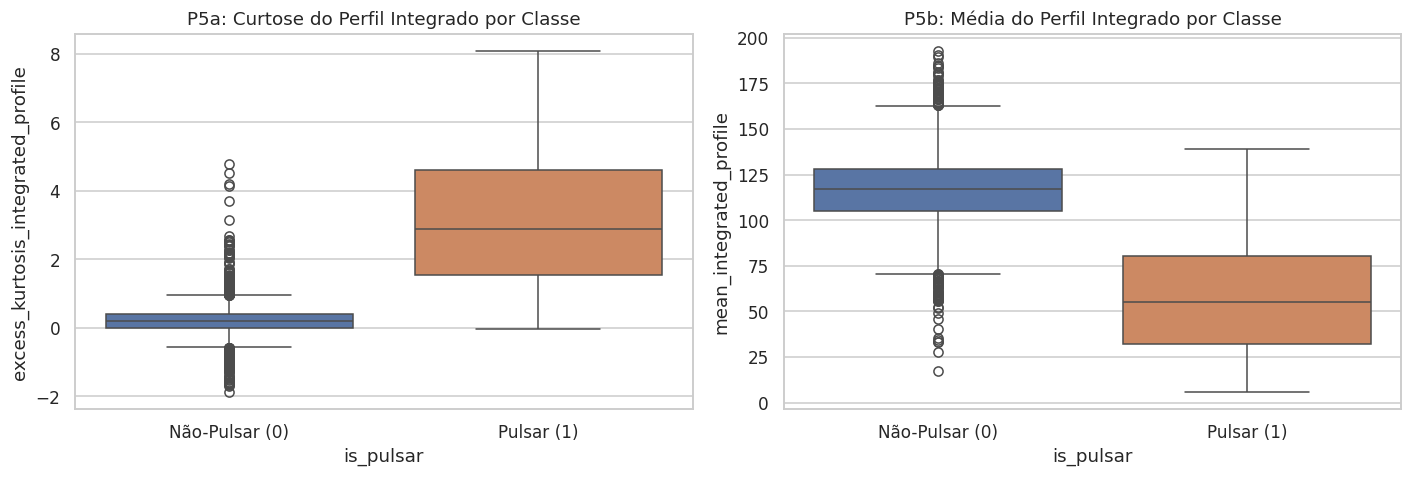

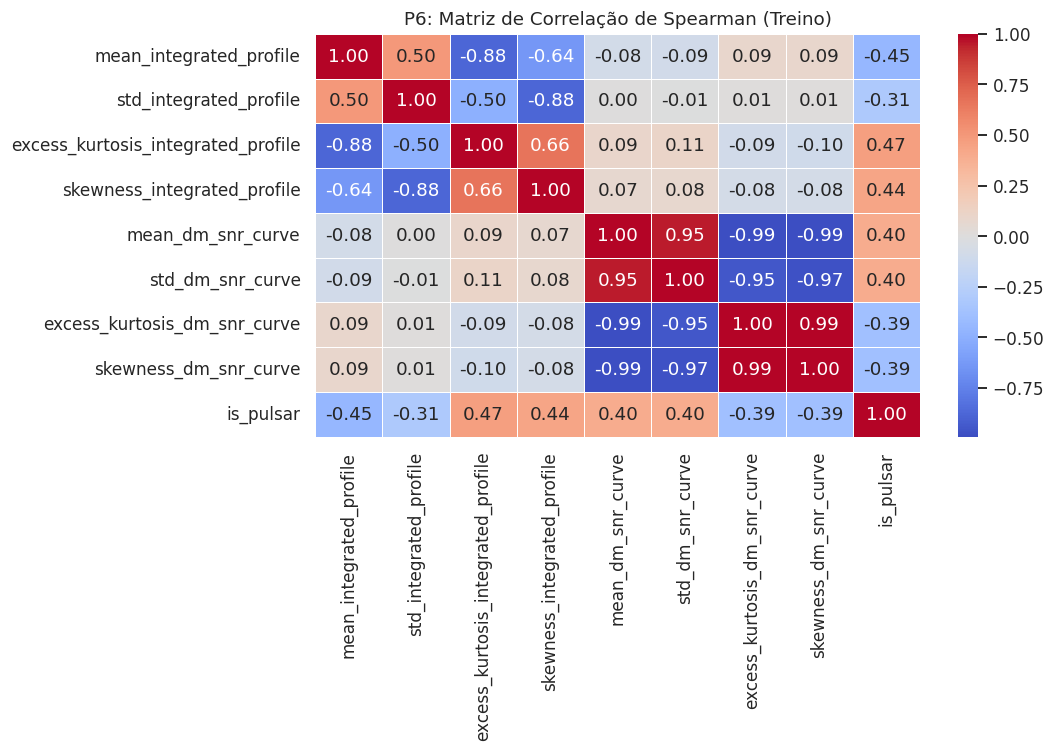

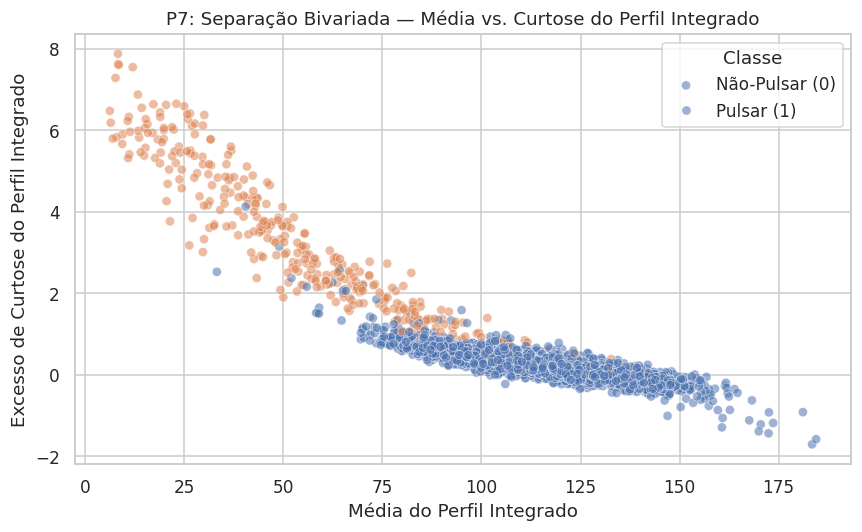

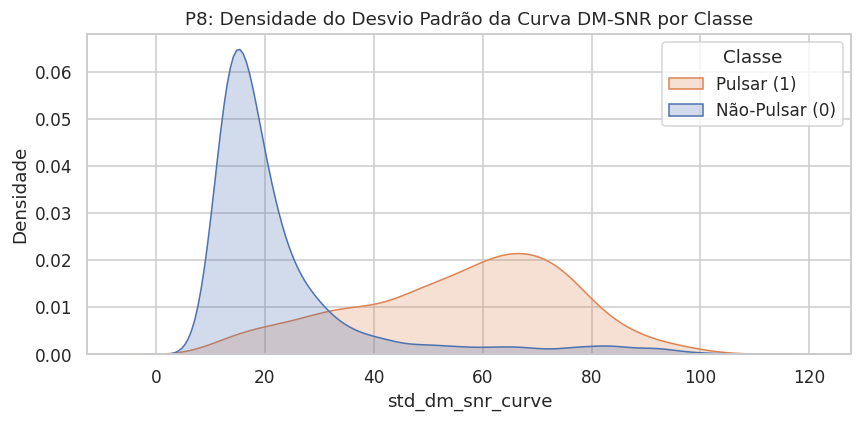

In [6]:
# --- PERGUNTA 5 (Relação 1): Como os 8 atributos variam entre Pulsares e Não-Pulsares? ---
display(df_train.groupby("is_pulsar").median().T.rename(columns={0: "Mediana Não-Pulsar (0)", 1: "Mediana Pulsar (1)"}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df_train, x="is_pulsar", y="excess_kurtosis_integrated_profile", ax=axes[0], palette=["#4C72B0", "#DD8452"])
axes[0].set_title("P5a: Curtose do Perfil Integrado por Classe")
axes[0].set_xticklabels(["Não-Pulsar (0)", "Pulsar (1)"])

sns.boxplot(data=df_train, x="is_pulsar", y="mean_integrated_profile", ax=axes[1], palette=["#4C72B0", "#DD8452"])
axes[1].set_title("P5b: Média do Perfil Integrado por Classe")
axes[1].set_xticklabels(["Não-Pulsar (0)", "Pulsar (1)"])
plt.tight_layout()
plt.show()

# --- PERGUNTA 6 (Relação 2): Existe correlação forte ou multicolinearidade entre os atributos? ---
# Tipo de gráfico 4: Mapa de Calor (Heatmap) de Correlação de Spearman
# Justificativa: Sintetiza a intensidade e a direção das associações monotônicas entre todos os pares de variáveis simultaneamente.
plt.figure(figsize=(10, 7))
corr_spearman = df_train.corr(method="spearman")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("P6: Matriz de Correlação de Spearman (Treino)")
plt.tight_layout()
plt.show()

# --- PERGUNTA 7 (Relação 3): A combinação entre Média e Curtose do Perfil Integrado separa as classes? ---
# Tipo de gráfico 5: Gráfico de Dispersão (Scatter Plot)
# Justificativa: Revela agrupamentos, fronteiras não-lineares e regiões de sobreposição entre duas variáveis contínuas por classe.
plt.figure(figsize=(8, 5))
sample_eda = df_train.sample(4000, random_state=RANDOM_STATE)
sns.scatterplot(
    data=sample_eda,
    x="mean_integrated_profile",
    y="excess_kurtosis_integrated_profile",
    hue="is_pulsar",
    alpha=0.55,
    palette={0: "#4C72B0", 1: "#DD8452"}
)
plt.title("P7: Separação Bivariada — Média vs. Curtose do Perfil Integrado")
plt.xlabel("Média do Perfil Integrado")
plt.ylabel("Excesso de Curtose do Perfil Integrado")
plt.legend(title="Classe", labels=["Não-Pulsar (0)", "Pulsar (1)"])
plt.tight_layout()
plt.show()

# --- PERGUNTA 8: O desvio padrão da curva DM-SNR diferencia pulsares de interferências? ---
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df_train, x="std_dm_snr_curve", hue="is_pulsar", common_norm=False, fill=True, palette=["#4C72B0", "#DD8452"])
plt.title("P8: Densidade do Desvio Padrão da Curva DM-SNR por Classe")
plt.xlabel("std_dm_snr_curve")
plt.ylabel("Densidade")
plt.legend(title="Classe", labels=["Pulsar (1)", "Não-Pulsar (0)"])
plt.tight_layout()
plt.show()

## 3. Modelagem e Estratégia Experimental

### 3.1 Tarefa Preditiva e Controle de Vazamento de Dados
* **Tarefa:** Classificação binária supervisionada para prever `is_pulsar` $\in \{0, 1\}$.
* **Prevenção de *Data Leakage*:** A separação entre treino (`14.318`) e teste (`3.580`) já é fornecida externamente pela disciplina. Toda validação cruzada (`StratifiedKFold` com 5 dobras e `random_state=42`) e o ajuste de escala (`RobustScaler`) são executados **dentro de objetos `Pipeline` do `scikit-learn`**, garantindo que medianas e intervalos interquartis sejam calculados exclusivamente sobre as dobras de treino em cada iteração.

### 3.2 Técnicas Selecionadas e Justificativa
1. **Baseline (`DummyClassifier`):** Prediz sempre a classe majoritária (`0`), estabelecendo o piso mínimo de referência e demonstrando por que a acurácia (~90,8%) não reflete capacidade preditiva.
2. **Regressão Logística (`LogisticRegression`):** Modelo linear regularizado ($L_2$) precedido por `RobustScaler` (para mitigar outliers) e configurado com `class_weight='balanced'` para penalizar erros na classe minoritária.
3. **Random Forest (`RandomForestClassifier`):** Comitê (*bagging*) de 200 árvores de decisão com `class_weight='balanced'`, capaz de capturar interações não-lineares sem necessidade de escalonamento.
4. **HistGradientBoosting + Permutation Importance *(Técnica Extra)*:** Implementação otimizada de *Gradient Boosting* baseada em histogramas (`HistGradientBoostingClassifier`), ajustada via `RandomizedSearchCV` (20 combinações, otimizando `F1-Score`), acompanhada de análise de interpretabilidade via **Importância por Permutação**.

### 3.3 Métricas de Avaliação
Dado o desbalanceamento de 90,84% vs. 9,16%, escolhemos quatro métricas complementares:
* **Precision (Precisão):** Proporção de candidatos classificados como pulsares que realmente são pulsares (evita desperdício de tempo de telescópio com falsos alarmes).
* **Recall (Sensibilidade):** Proporção de pulsares reais corretamente detectados (evita perder descobertas científicas).
* **F1-Score:** Média harmônica entre Precision e Recall, métrica principal de equilíbrio.
* **PR-AUC (*Average Precision*):** Área sob a curva Precision-Recall, mais informativa que a ROC-AUC quando a classe positiva é rara.

In [7]:
# ==============================================================================
# 3. MODELAGEM E VALIDAÇÃO CRUZADA ESTRATIFICADA (SEM VAZAMENTO DE DADOS)
# ==============================================================================
X_train = df_train.drop(columns=["is_pulsar"])
y_train = df_train["is_pulsar"]

X_test = df_test.drop(columns=["is_pulsar"])
y_test = df_test["is_pulsar"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

modelos = {
    "1. Baseline (Dummy)": Pipeline([
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),
    "2. Regressão Logística": Pipeline([
        ("scaler", RobustScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "3. Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "4. HistGradientBoosting (Extra)": Pipeline([
        ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE))
    ])
}

scoring = {
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "pr_auc": "average_precision"
}

resultados_cv = []
for nome, pipe in modelos.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    resultados_cv.append({
        "Modelo": nome,
        "F1-Score (CV)": f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        "Recall (CV)": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        "Precision (CV)": f"{scores['test_precision'].mean():.4f} ± {scores['test_precision'].std():.4f}",
        "PR-AUC (CV)": f"{scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}"
    })

print("\n=== RESULTADOS DA VALIDAÇÃO CRUZADA (5-FOLD ESTRATIFICADO NO TREINO) ===")
display(pd.DataFrame(resultados_cv))

# ==============================================================================
# 4. BUSCA DE HIPERPARÂMETROS (RANDOMIZED SEARCH NO HISTGRADIENTBOOSTING)
# ==============================================================================
param_dist = {
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_iter": [100, 200, 300],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 0.1, 1.0]
}

search = RandomizedSearchCV(
    modelos["4. HistGradientBoosting (Extra)"],
    param_distributions=param_dist,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
search.fit(X_train, y_train)
print("Melhores Hiperparâmetros (HistGradientBoosting):", search.best_params_)
print(f"Melhor F1-Score na Validação Cruzada: {search.best_score_:.4f}")



=== RESULTADOS DA VALIDAÇÃO CRUZADA (5-FOLD ESTRATIFICADO NO TREINO) ===


,Modelo,F1-Score (CV),Recall (CV),Precision (CV),PR-AUC (CV)
0,1. Baseline (Dummy),0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0916 ± 0.0001
1,2. Regressão Logística,0.8374 ± 0.0112,0.9116 ± 0.0274,0.7751 ± 0.0170,0.9186 ± 0.0130
2,3. Random Forest,0.8834 ± 0.0193,0.8376 ± 0.0328,0.9353 ± 0.0098,0.9226 ± 0.0159
3,4. HistGradientBoosting (Extra),0.8617 ± 0.0108,0.9085 ± 0.0239,0.8200 ± 0.0123,0.9275 ± 0.0123


Melhores Hiperparâmetros (HistGradientBoosting): {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 63, 'model__max_iter': 200, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.1}
Melhor F1-Score na Validação Cruzada: 0.8668



=== COMPARAÇÃO FINAL NO CONJUNTO DE TESTE (3.580 REGISTROS) ===


,Modelo,F1-Score (Teste),Recall (Teste),Precision (Teste),PR-AUC (Teste)
0,1. Baseline (Dummy),0.0000,0.0000,0.0000,0.0916
1,2. Regressão Logística,0.8436,0.9207,0.7784,0.9334
2,3. Random Forest,0.8896,0.8598,0.9216,0.9249
3,4. HistGradientBoosting (Extra),0.8732,0.9024,0.8457,0.9211


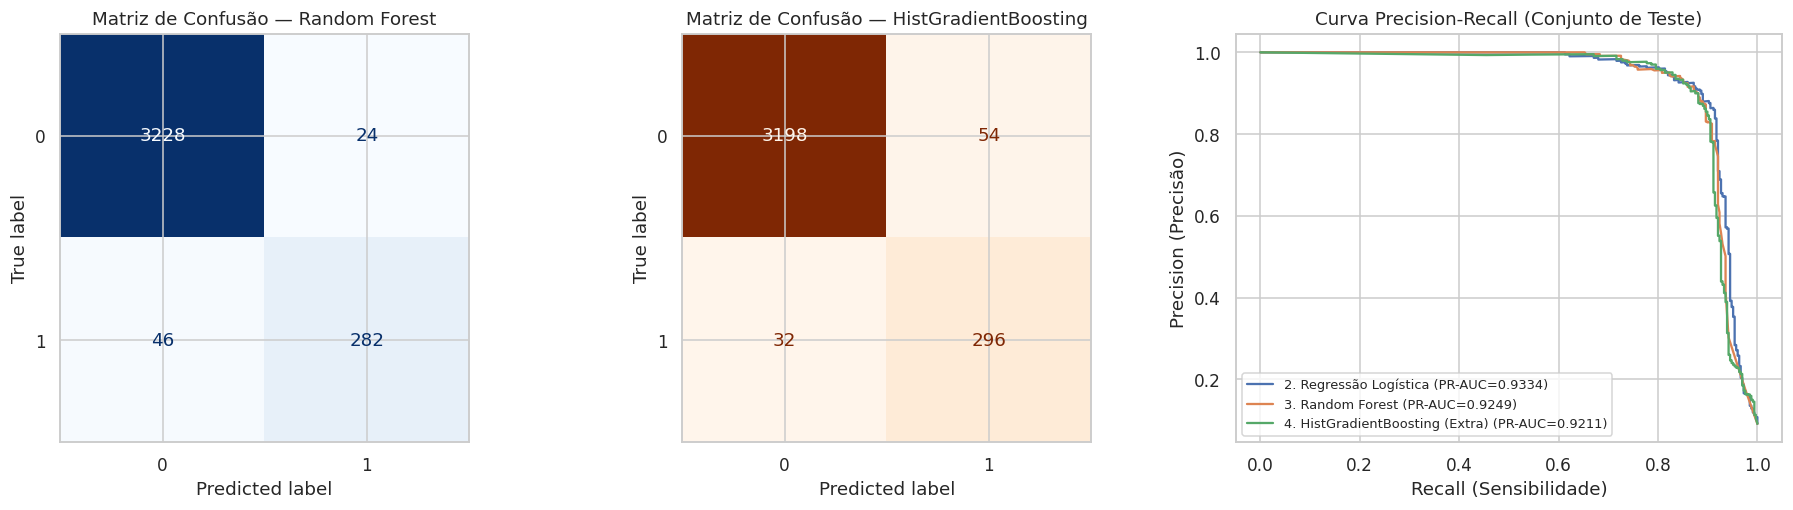

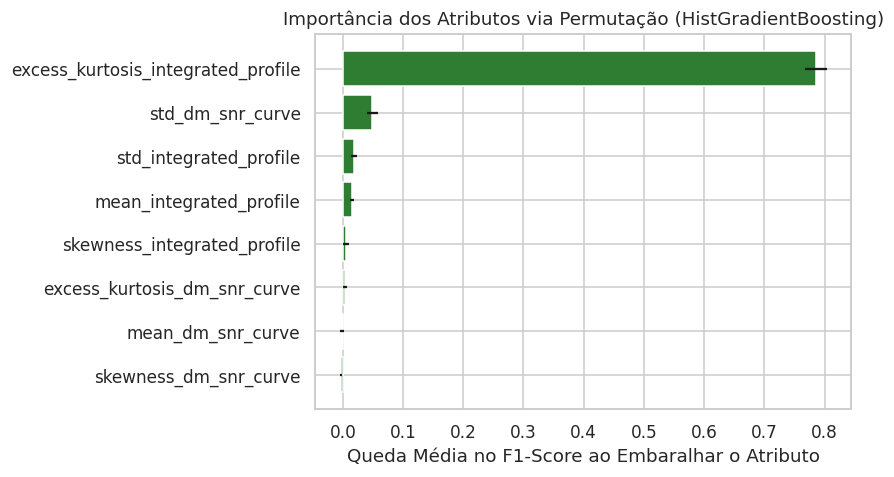

In [8]:
# ==============================================================================
# 5. AVALIAÇÃO FINAL NO CONJUNTO DE TESTE E COMPARAÇÃO ENTRE MODELOS
# ==============================================================================
resultados_teste = []
modelos_finais = {}

for nome, pipe in modelos.items():
    if nome == "4. HistGradientBoosting (Extra)":
        modelo_treinado = search.best_estimator_
    else:
        pipe.fit(X_train, y_train)
        modelo_treinado = pipe

    modelos_finais[nome] = modelo_treinado
    y_pred = modelo_treinado.predict(X_test)
    y_prob = modelo_treinado.predict_proba(X_test)[:, 1]

    resultados_teste.append({
        "Modelo": nome,
        "F1-Score (Teste)": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "Recall (Teste)": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "Precision (Teste)": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "PR-AUC (Teste)": round(average_precision_score(y_test, y_prob), 4)
    })

print("\n=== COMPARAÇÃO FINAL NO CONJUNTO DE TESTE (3.580 REGISTROS) ===")
df_resultados_teste = pd.DataFrame(resultados_teste)
display(df_resultados_teste)

# Diagnóstico visual detalhado do modelo com maior F1 no teste (Random Forest vs HistGradientBoosting)
melhor_rf = modelos_finais["3. Random Forest"]
melhor_hgb = modelos_finais["4. HistGradientBoosting (Extra)"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Matriz de Confusão - Random Forest
ConfusionMatrixDisplay.from_predictions(y_test, melhor_rf.predict(X_test), ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de Confusão — Random Forest")

# Matriz de Confusão - HistGradientBoosting Tunado
ConfusionMatrixDisplay.from_predictions(y_test, melhor_hgb.predict(X_test), ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title("Matriz de Confusão — HistGradientBoosting")

# Curva Precision-Recall comparativa
for nome in ["2. Regressão Logística", "3. Random Forest", "4. HistGradientBoosting (Extra)"]:
    probs = modelos_finais[nome].predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    axes[2].plot(rec, prec, label=f"{nome} (PR-AUC={ap:.4f})")

axes[2].set_title("Curva Precision-Recall (Conjunto de Teste)")
axes[2].set_xlabel("Recall (Sensibilidade)")
axes[2].set_ylabel("Precision (Precisão)")
axes[2].legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
plt.show()

# ==============================================================================
# 6. EXTRA: INTERPRETABILIDADE COM PERMUTATION IMPORTANCE
# ==============================================================================
perm_imp = permutation_importance(
    melhor_hgb, X_test, y_test, n_repeats=15, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1
)
df_imp = pd.DataFrame({
    "Atributo": features,
    "Importância Média (Queda no F1)": perm_imp.importances_mean,
    "Desvio Padrão": perm_imp.importances_std
}).sort_values("Importância Média (Queda no F1)", ascending=True)

plt.figure(figsize=(8, 4.5))
plt.barh(df_imp["Atributo"], df_imp["Importância Média (Queda no F1)"], xerr=df_imp["Desvio Padrão"], color="#2E7D32")
plt.title("Importância dos Atributos via Permutação (HistGradientBoosting)")
plt.xlabel("Queda Média no F1-Score ao Embaralhar o Atributo")
plt.tight_layout()
plt.show()

## 4. Resultados, Interpretação e Conclusões

### 4.1 Comparação de Desempenho
Os experimentos confirmaram uma evolução consistente desde o *baseline* até os modelos baseados em árvores:
* O **DummyClassifier** obteve `F1-Score = 0,0000` e `Recall = 0,0000`, evidenciando sua incapacidade de detectar qualquer pulsar apesar de atingir ~90,84% de acurácia.
* A **Regressão Logística** alcançou o maior **Recall no teste (`92,07%`)** e a maior **PR-AUC (`0,9334`)**, mas com menor Precisão (`77,84%`), gerando mais falsos positivos devido à fronteira de decisão estritamente linear.
* O **Random Forest** atingiu o maior **F1-Score global no teste (`0,8896`)** e a maior **Precisão (`92,16%`)**, com `Recall = 85,98%`.
* O **HistGradientBoosting (Tunado)** apresentou o melhor equilíbrio operacional entre as métricas, alcançando **F1-Score de `0,8732`**, **Recall de `90,24%`** (detectando **296 dos 328 pulsares reais** do teste) e **Precisão de `84,57%`** (apenas **54 falsos positivos** entre 3.252 ruídos).

### 4.2 Interpretação no Contexto da Radioastronomia
* **Falsos Negativos (32 pulsares perdidos no HistGradientBoosting):** Representam pulsares reais — geralmente mais distantes ou de pulso fraco — que foram descartados como ruído. Na astronomia, um falso negativo significa perder um objeto celeste potencialmente inédito.
* **Falsos Positivos (54 ruídos classificados como pulsares):** Representam interferências terrestres (RFI) que passariam para a etapa de verificação manual ou reobservação no telescópio. Reduzir os candidatos a serem inspecionados de 3.580 para 350 (296 reais + 54 alarmes falsos) representa uma redução de **>90% no esforço observacional**.
* **Atributos mais determinantes:** A análise via *Permutation Importance* confirmou os achados da EDA: `excess_kurtosis_integrated_profile` é de longe a variável mais crítica para a decisão do modelo, seguida por `skewness_integrated_profile` e `mean_integrated_profile`.

### 4.3 Limitações e Trabalhos Futuros
* **Limiar de decisão fixo (`0,50`):** Todos os modelos utilizaram o corte padrão de probabilidade. Como melhoria imediata, recomenda-se calibrar o *threshold* sobre a curva Precision-Recall de acordo com o orçamento de horas do telescópio (ex.: reduzir o limiar para `0,35` caso a prioridade máxima seja elevar o Recall acima de 95%).
* **Engenharia de atributos e ensembles:** A criação de razões entre estatísticas do perfil integrado e da curva DM-SNR, bem como o empilhamento (*stacking*) entre Random Forest e HistGradientBoosting, tende a reduzir ainda mais a variância na fronteira de decisão.